## 1. Objetivos, fuente y metodología
Se utilizan los 21,613 registros del archivo proporcionado. Se descartan `id`, `date` y `zipcode` por su interpretación como identificadores/ubicación categórica; `sqft_above` y `sqft_basement` se excluyen por la identidad `sqft_living = sqft_above + sqft_basement`, que introduce dependencia lineal exacta si se incluyen simultáneamente. `lat` y `long` representan ubicación como coordenadas numéricas. Se emplea separación 80/20 con semilla 42 para evaluar generalización. La selección de variables se realiza **solo sobre entrenamiento**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as tdist
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")
import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 53")

df = pd.read_csv("kc_house_data.csv")


print("Dimensiones:", df.shape); display(df.head()); print(df.isna().sum())

Dimensiones: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


## 2. Análisis exploratorio

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1000102.00,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,75000.00,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370000e+00,9.300000e-01,0.00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.110000e+00,7.700000e-01,0.00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184400e+02,290.00,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,520.00,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.490000e+00,5.400000e-01,1.00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,1.000000e-02,9.000000e-02,0.00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.300000e-01,7.700000e-01,0.00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.410000e+00,6.500000e-01,1.00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


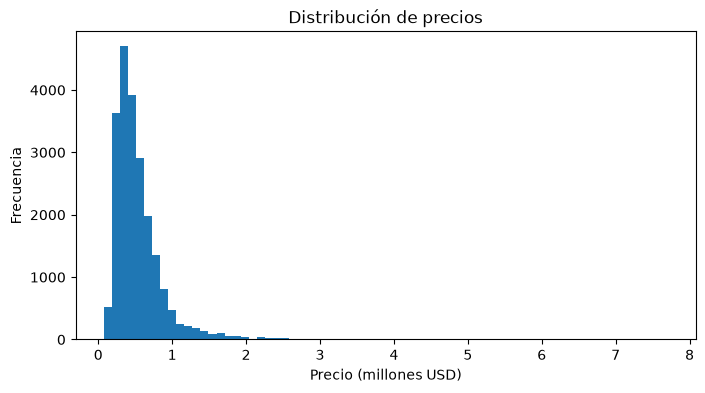

In [2]:
display(df.describe().T.round(2))
fig,ax=plt.subplots(figsize=(8,4));
ax.hist(df.price/1e6,bins=70);
ax.set(xlabel="Precio (millones USD)",ylabel="Frecuencia",title="Distribución de precios");
plt.show()

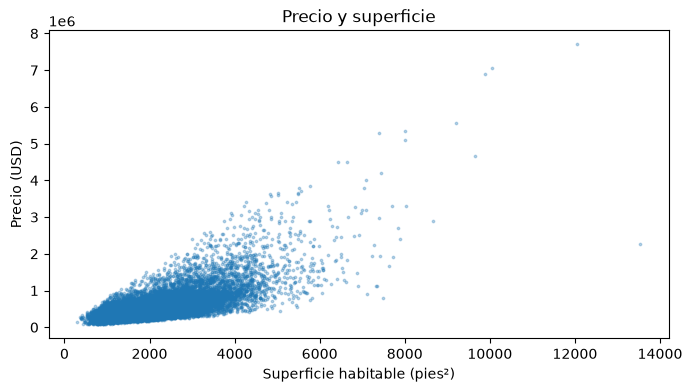

In [3]:
fig,ax=plt.subplots(figsize=(8,4));
ax.scatter(df.sqft_living,df.price,s=3,alpha=.3);
ax.set(xlabel="Superficie habitable (pies²)",ylabel="Precio (USD)",title="Precio y superficie");
plt.show()

## 3. Modelo matricial e inferencia
Sea $X$ la matriz de diseño con intercepto y $y$ el vector de precios. Estimamos $\hat\beta=(X^TX)^{-1}X^Ty$, implementado mediante `np.linalg.lstsq` para mayor estabilidad numérica. La matriz de covarianza estimada es $\hat\sigma^2(X^TX)^{-1}$, con $\hat\sigma^2=RSS/(n-p)$. Cada prueba contrasta $H_0: \beta_j=0$ frente a $H_1: \beta_j\ne0$. Se estandarizan predictores con parámetros calculados **solo en entrenamiento** para mejorar el condicionamiento; los contrastes t de pendientes no cambian por ese reescalamiento.

In [4]:
features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 
            'lat', 'long', 'sqft_living15', 'sqft_lot15']
train,test=train_test_split(df,test_size=.2,random_state=42)
mu=train[features].mean();sd=train[features].std().replace(0,1)
def fit_matrix(cols):
    X=np.column_stack([np.ones(len(train)),((train[cols]-mu[cols])/sd[cols]).to_numpy()]);y=train.price.to_numpy()
    beta=np.linalg.lstsq(X,y,rcond=None)[0]
    residual=y-X@beta;n,p=X.shape;dof=n-p
    s2=(residual@residual)/dof
    cov=s2*np.linalg.inv(X.T@X)
    se=np.sqrt(np.diag(cov)); t_stat=beta/se
    p_values=2*tdist.sf(np.abs(t_stat),dof)
    critical=tdist.ppf(.975,dof)
    ci=np.column_stack([beta-critical*se,beta+critical*se])
    return beta,se,t_stat,p_values,ci,dof
print("Variables iniciales:",features)

Variables iniciales: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


## 4. StepWise: eliminación hacia atrás
Se retira iterativamente el predictor con el mayor valor p si supera $\alpha=0.05$. El intercepto permanece. Este procedimiento es una modalidad **backward** de selección StepWise, no una búsqueda exhaustiva ni una selección bidireccional. Sus valores p posteriores a la selección deben interpretarse como exploratorios, pues no ajustan por selección múltiple.

In [5]:
selected=features.copy();history=[]
while True:
    beta,se,t_stat,p_values,ci,dof=fit_matrix(selected)
    i=int(np.argmax(p_values[1:]));worst=float(p_values[i+1])
    if worst<=0.05:break
    history.append((selected.pop(i),worst))
print("Eliminadas (variable, p al eliminar):",history)
print("Seleccionadas:",selected)

Eliminadas (variable, p al eliminar): [('sqft_lot', 0.10704142594353848)]
Seleccionadas: ['bedrooms', 'bathrooms', 'sqft_living', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


## 5. Tres enfoques de pruebas de hipótesis
**Enfoque 1 (t crítico):** rechazar $H_0$ si $|t_j|>t_{0.975,n-p}$. **Enfoque 2 (p):** rechazar si $p_j<0.05$. **Enfoque 3 (IC95):** rechazar si el intervalo no contiene cero. Para una prueba bilateral al 5 %, los tres criterios son matemáticamente equivalentes para el mismo ajuste.

In [6]:
beta,se,t_stat,p_values,ci,dof=fit_matrix(selected)
critical=tdist.ppf(.975,dof)
result=pd.DataFrame({"variable":["Intercepto"]+selected,"beta":beta,"SE":se,"t":t_stat,"p":p_values,"IC95_inf":ci[:,0],"IC95_sup":ci[:,1]})
result["t_critico"]=critical
result["significativo_t"]=np.abs(result.t)>critical
result["significativo_p"]=result.p<.05
result["significativo_IC"]=~((result.IC95_inf<=0)&(result.IC95_sup>=0))
display(result.round(5));print("t crítico bilateral:",critical,"grados de libertad:",dof)
assert (result.significativo_t==result.significativo_p).all() and (result.significativo_p==result.significativo_IC).all()

,variable,beta,SE,t,p,IC95_inf,IC95_sup,t_critico,significativo_t,significativo_p,significativo_IC
0,Intercepto,537768.04795,1520.61315,353.65211,0.00000,534787.49210,540748.60380,1.9601,True,True,True
1,bedrooms,-30808.41331,1952.61532,-15.77802,0.00000,-34635.73717,-26981.08945,1.9601,True,True,True
2,bathrooms,31998.14601,2753.95598,11.61898,0.00000,26600.11327,37396.17874,1.9601,True,True,True
3,sqft_living,151311.10308,3392.19870,44.60561,0.00000,144662.04993,157960.15622,1.9601,True,True,True
4,floors,7144.16283,1937.45104,3.68740,0.00023,3346.56249,10941.76317,1.9601,True,True,True
5,waterfront,48316.13239,1658.33402,29.13534,0.00000,45065.62970,51566.63509,1.9601,True,True,True
6,view,36507.46744,1779.69991,20.51327,0.00000,33019.07529,39995.85958,1.9601,True,True,True
7,condition,17787.01838,1685.29374,10.55425,0.00000,14483.67190,21090.36486,1.9601,True,True,True
8,grade,114814.37693,2767.86314,41.48123,0.00000,109389.08475,120239.66911,1.9601,True,True,True
9,yr_built,-74966.84892,2360.22281,-31.76262,0.00000,-79593.12476,-70340.57307,1.9601,True,True,True


t crítico bilateral: 1.9601013179481683 grados de libertad: 17275


## 6. Pronóstico y métricas en datos no utilizados para ajustar ni seleccionar
Las métricas $R^2$, MAE y RMSE se calculan sobre el conjunto de prueba. El desempeño no prueba causalidad ni garantiza validez de los supuestos de errores independientes, homocedásticos y normales.

In [7]:
def predict(frame,cols,beta):
    X=np.column_stack([np.ones(len(frame)),((frame[cols]-mu[cols])/sd[cols]).to_numpy()]);return X@beta
y_test=test.price.to_numpy();pred=predict(test,selected,beta)
full_beta=fit_matrix(features)[0];pred_full=predict(test,features,full_beta)
summary=pd.DataFrame({"Modelo":["Completo","StepWise"],"R2":[r2_score(y_test,pred_full),r2_score(y_test,pred)],"MAE_USD":[mean_absolute_error(y_test,pred_full),mean_absolute_error(y_test,pred)],"RMSE_USD":[np.sqrt(mean_squared_error(y_test,pred_full)),np.sqrt(mean_squared_error(y_test,pred))]})
display(summary.round(3))

,Modelo,R2,MAE_USD,RMSE_USD
0,Completo,0.695,128062.817,214744.877
1,StepWise,0.695,128195.576,214850.210


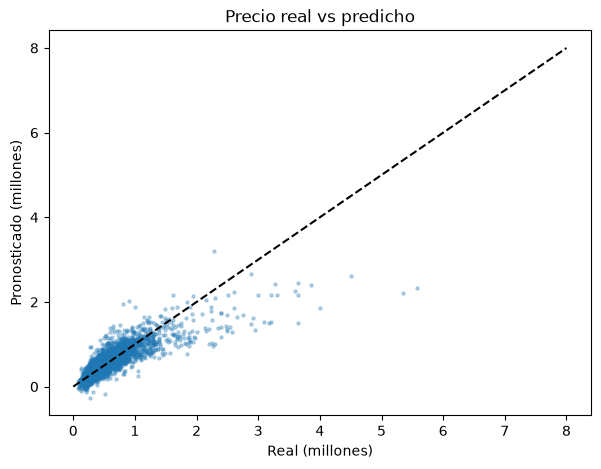

In [8]:
fig,ax=plt.subplots(figsize=(7,5));ax.scatter(y_test/1e6,pred/1e6,s=5,alpha=.3);ax.plot([0,8],[0,8],"k--");
ax.set(xlabel="Real (millones)",ylabel="Pronosticado (millones)",title="Precio real vs predicho");
plt.show()

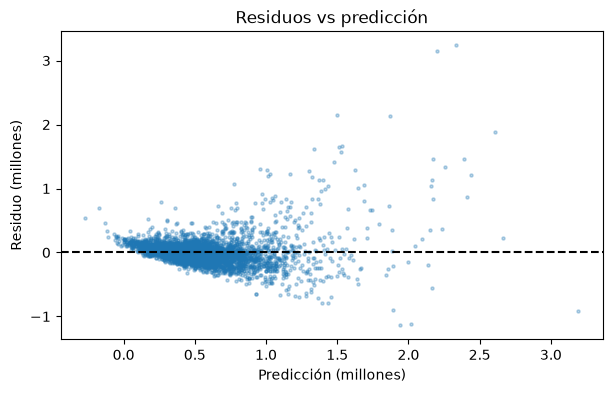

In [9]:
fig,ax=plt.subplots(figsize=(7,4));
ax.scatter(pred/1e6,(y_test-pred)/1e6,s=5,alpha=.3);
ax.axhline(0,color="black",ls="--");
ax.set(xlabel="Predicción (millones)",ylabel="Residuo (millones)",title="Residuos vs predicción");
plt.show()

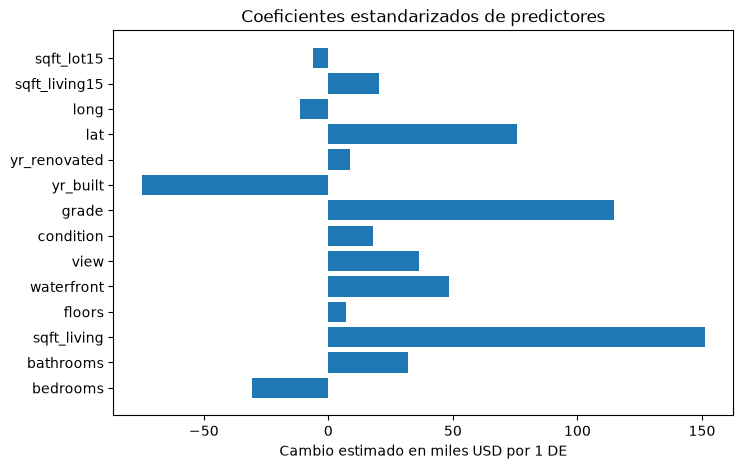

In [10]:
fig,ax=plt.subplots(figsize=(8,5));
ax.barh(selected,beta[1:]/1000);
ax.set(xlabel="Cambio estimado en miles USD por 1 DE",title="Coeficientes estandarizados de predictores");
plt.show()

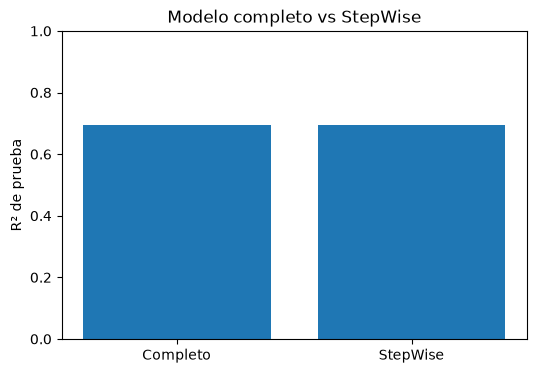

In [11]:
fig,ax=plt.subplots(figsize=(6,4));
ax.bar(summary["Modelo"],summary["R2"]);
ax.set(ylim=(0,1),ylabel="R² de prueba",title="Modelo completo vs StepWise");
plt.show()

## 7. Interpretación y limitaciones
La significancia estadística significa evidencia de asociación parcial distinta de cero bajo los supuestos del modelo; no implica causalidad ni importancia económica. Los coeficientes se interpretan como cambio en USD ante una desviación estándar del predictor, manteniendo constantes los demás. El intercepto representa el precio estimado cuando los predictores toman sus medias de entrenamiento.

**Limitaciones:** selección automática puede sesgar inferencias; las observaciones de viviendas pueden presentar heterocedasticidad, valores extremos, no linealidad y dependencia espacial. Un siguiente paso sería verificar VIF, usar errores estándar robustos, comparar validación cruzada y considerar transformaciones de precio y modelos no lineales.

In [12]:
print("CONCLUSIONES AUTOMÁTICAS")
print("Variables eliminadas:",history if history else "Ninguna")
print("Variables finales:",selected)
print(f"R² prueba={r2_score(y_test,pred):.4f}; MAE=${mean_absolute_error(y_test,pred):,.2f}; RMSE=${np.sqrt(mean_squared_error(y_test,pred)):,.2f}")
print("Los tres enfoques coinciden:",bool((result.significativo_t==result.significativo_p).all() and (result.significativo_p==result.significativo_IC).all()))
result.to_csv("resultados_coeficientes.csv",index=False)

CONCLUSIONES AUTOMÁTICAS
Variables eliminadas: [('sqft_lot', 0.10704142594353848)]
Variables finales: ['bedrooms', 'bathrooms', 'sqft_living', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
R² prueba=0.6947; MAE=$128,195.58; RMSE=$214,850.21
Los tres enfoques coinciden: True
